# 0050：融資維持率 diff 與動態 window
## tl;dr
2023-03-01 至 2026-10-14，每月入金 1 萬、訊號買入 10 萬，累計入金 44 萬。固定 20 日 diff 期末 83.10 萬；依波動調整 window 為 82.13 萬；固定 window 標準化 diff 為 79.67 萬；定期定額為 114.23 萬。均含現金。

**這組資料沒有顯示動態 window 的穩定優勢。** 固定與動態版各買四次，其中三次相同，差異主要來自第二筆買入時點。參數改變會改變三者排名，不能挑最高值稱為最佳策略。這是已看過行情的探索，並非樣本外驗證。
## Context & Methods
### Key Assumptions
- 共用 1,200 筆上市維持率（含 ETF），2021-11-03 至 2026-10-14。2023-03-01 起才開始入金及計績效，前段只作暖機，不累積現金。
- 低水準條件：當日維持率低於「截至昨日的 252 筆維持率」第 10 百分位。三種 diff 方法完全相同，另有只有低水準條件及固定 140/150/160% 對照。
- 固定 diff：M[t] - M[t-20] < -10 個百分點。
- 標準化 diff：(M[t] - M[t-20]) / (sigma[t] * sqrt(20)) < -1.5；不是常態機率或顯著性檢定。
- sigma[t]：截至昨日最近 60 筆每日維持率變動的樣本標準差。sigma_ref[t]：截至昨日最近 252 筆 sigma 的中位數。
- 動態 window：round(clip(20 * (sigma_ref/sigma)^2, 5, 60))；每天更新，主版本不限制變動步長。波動大時縮短視窗。以 M[t] - M[t-window] < -10 判斷。
- 每個完整買入條件由 false 變成 true 才觸發；條件持續成立不重複買。這不是固定冷卻期，也沒有恢復至第 30 百分位才重啟的機制。
- 訊號盤後取得，下一個 0050 可交易日開盤買入。每月首個可交易日入金 1 萬元，每次買 10 萬（含費用），現金不足則跳過且不補買。初始無現金。
- 0050 使用前次已核對的含分割／配息調整行情；2025 年分割不重複調整，停牌日不交易。理論稅前配息再投入、可分割等值單位；非逐股、實際股息發放日的交易簿。
- 買入費率 0.1425%，現金利率基準 0%；無滑價、最低費用、個人配息稅。期末持有不賣出，無賣出費稅。
- XIRR 使用全部每月入金及期末股票加現金；回撤扣除入金影響並含現金，低回撤可能只來自持有較多現金。
- 基準參數未最佳化，敏感度列出較鬆／嚴門檻、10/40 日、頭尾 3 日平均、window 每天最多變動 1 天、每次買 5 萬、現金 2%。不同訊號門檻未匹配事件頻率。
- 三年低分位視窗另從 2025-01-02 開始比較，只有 22 個月入金，不能把該列金額與主表直接比較。
## Data
[愛玩股上市維持率歷史](https://www.istock.tw/post/twmarginrequirement_more)第 1～20 頁、前次透過公開頁面擷取，此次將完整日序列保存為 `../margin_daily.csv`。資料含 ETF，四捨五入至兩位；不是官方發布的逐戶擔保維持率，也不是全歷史官方逐股驗證結果。歷史頁面可能修訂，沒有當時發布時間快照。

[Yahoo 0050 行情](https://finance.yahoo.com/quote/0050.TW/history/)保存於 `../raw/0050-yahoo2.json`；已整理的 `../prices_reviewed.csv` 補入[證交所 2026-10-14](https://www.twse.com.tw/exchangeReport/MI_INDEX?response=json&date=20261014&type=ALLBUT0999)缺價。分割參考[元大說明](https://www.yuantafunds.com/active/ETF0050/index.html)。此次不重新下載行情，以固定快照比較。

資料核對：1,200 個日期完全對齊、轉存值校驗碼一致、重建的 44 個固定水位事件與前次一致。特徵的 400/800/1000 筆前綴計算與完整樣本相同，檢查未來資料不影響歷史特徵。這些檢查不等於驗證來源每筆歷史值。


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
import run_dynamic as bt
import contextlib,io
ROOT=Path.cwd()
with contextlib.redirect_stdout(io.StringIO()):
    summary,features=bt.main()
daily=pd.read_csv(ROOT/'daily.csv',parse_dates=['date'])
events=pd.read_csv(ROOT/'events.csv',parse_dates=['execution_date','signal_date'])
sensitivity=pd.read_csv(ROOT/'sensitivity.csv')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'figure.dpi':140})
colors={'DCA':'#202020','Low only':'#969696','fixed':'#0072B2','normalized':'#D55E00','dynamic':'#009E73'}
summary[['strategy','signals','buys','skips','nav','cash','xirr_pct','mdd_pct']].round(2)

,strategy,signals,buys,skips,nav,cash,xirr_pct,mdd_pct
0,DCA,44,44,0,1142311.67,0.0,58.31,-27.36
1,Level 140,1,1,0,646718.11,340000.0,22.01,-7.58
2,Level 150,4,2,2,788174.06,240000.0,34.08,-17.80
3,Level 160,14,3,11,797154.79,140000.0,34.79,-22.32
4,Low only,21,4,17,817070.02,40000.0,36.34,-22.41
5,fixed,9,4,5,830978.07,40000.0,37.40,-20.45
6,normalized,7,4,3,796736.70,40000.0,34.75,-17.39
7,dynamic,10,4,6,821306.11,40000.0,36.66,-22.33


## Results
### 相同資金規則的結果
主表 44 萬入金；三個 diff 版本都投入 40 萬、期末現金 4 萬。持倉期間及等待時間不同，會影響績效。

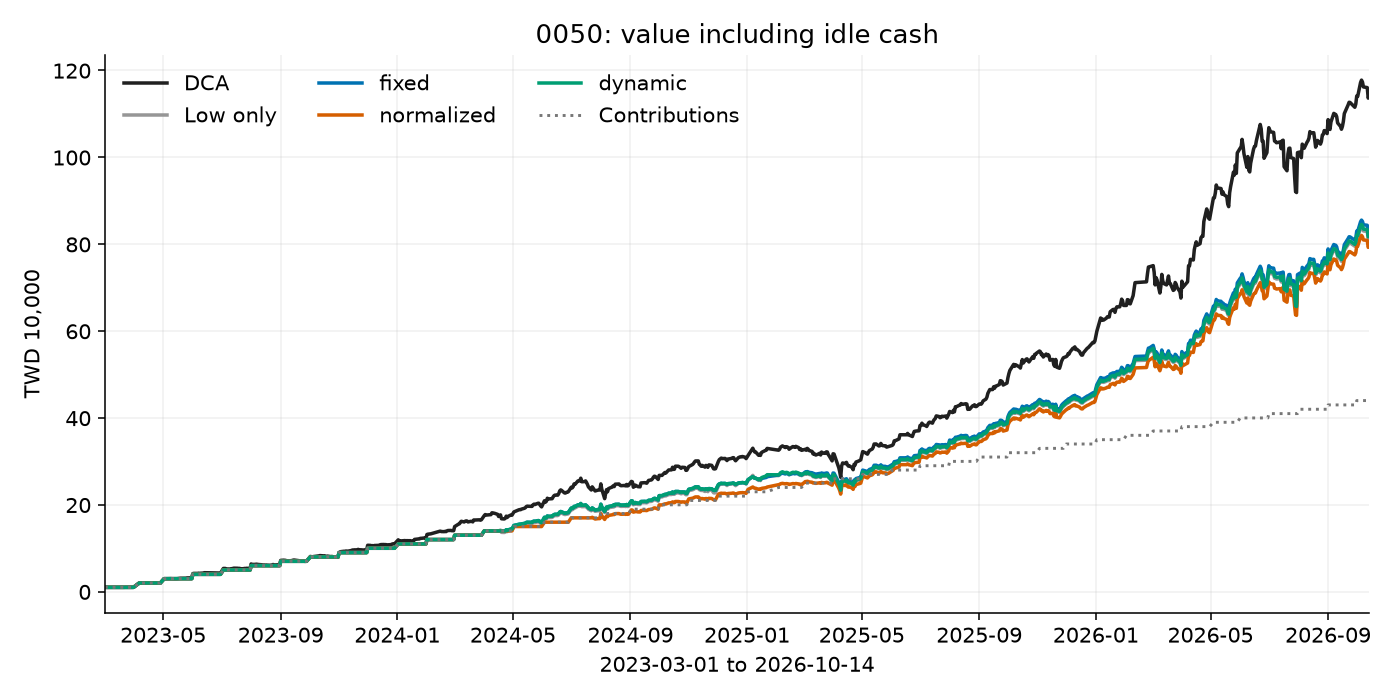

In [2]:
fig,ax=plt.subplots(figsize=(10,5))
for name in colors:
    g=daily[daily.strategy==name]
    ax.plot(g.date,g.nav/10000,label=name,color=colors[name],lw=1.8)
g=daily[daily.strategy=='DCA']
ax.plot(g.date,g.contributions/10000,':',color='#777777',label='Contributions')
ax.set(title='0050: value including idle cash',ylabel='TWD 10,000',xlabel='2023-03-01 to 2026-10-14',xlim=(bt.START,bt.END))
ax.legend(frameon=False,ncol=3,loc='upper left')
fig.tight_layout();fig.savefig(ROOT/'comparison.png');display(Image(filename=str(ROOT/'comparison.png')));plt.close(fig)

### 訊號與動態視窗
用實際執行的訊號日標記買入決策（成交於下一可交易日）。低水準條件會排除高水準急跌，window 縮短本身也會改變比較端點。

/var/folders/rc/7x6y_x8x1ydbghqxwrl9v3zr0000gn/T/ipykernel_89750/762115209.py:7: UserWarning: You passed an edgecolor/edgecolors ('#D55E00') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axes[0].scatter(dates,features.loc[dates,'ratio'],s=55,marker=marker,facecolors='none' if marker=='o' else colors[name],edgecolors=colors[name],label=name,zorder=3)


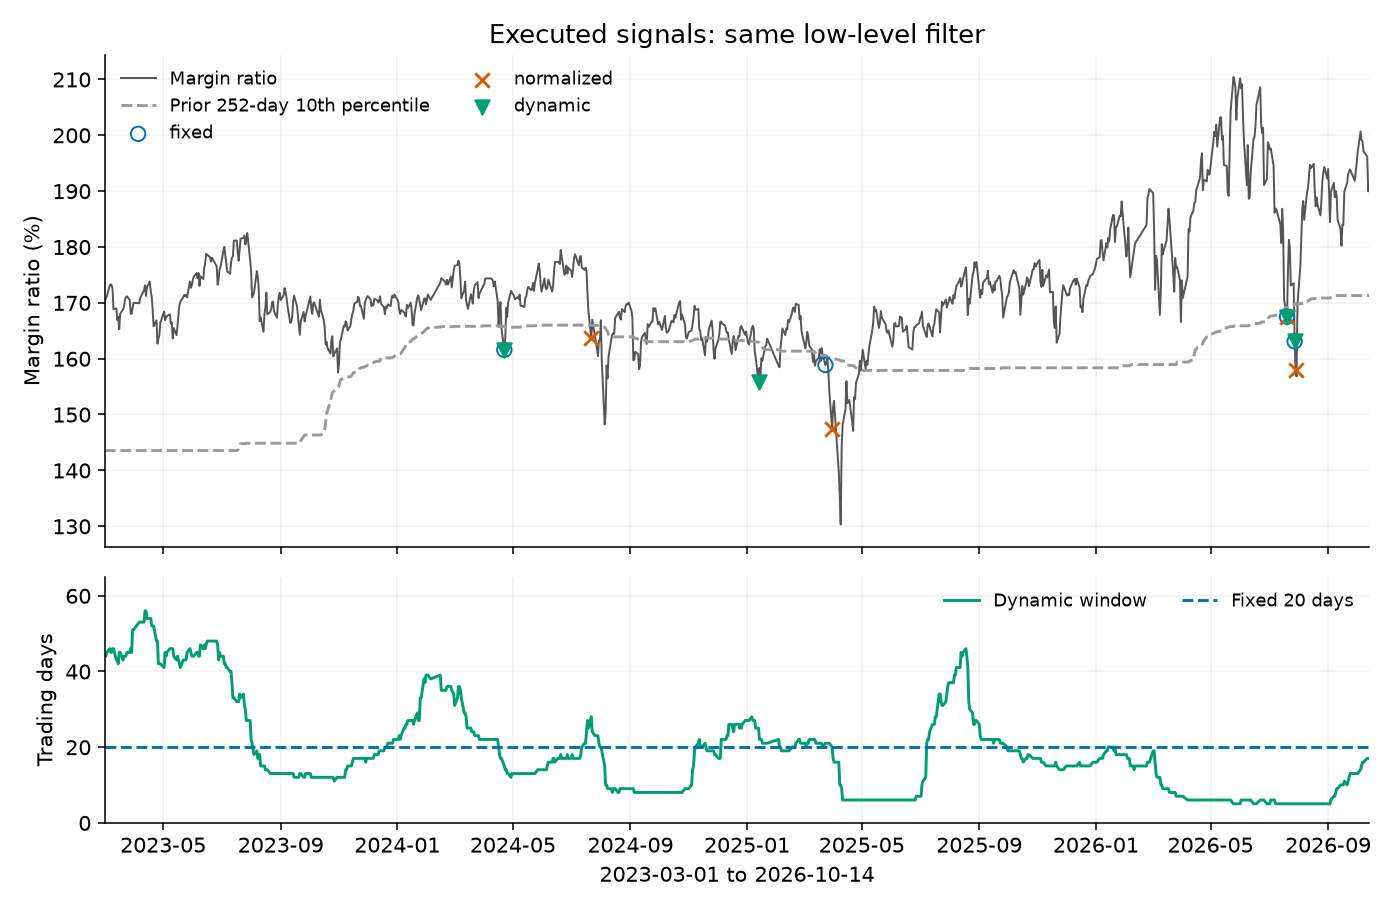

In [3]:
f=features.loc[bt.START:]
fig,axes=plt.subplots(2,1,figsize=(10,6.5),sharex=True,gridspec_kw={'height_ratios':[2,1]})
axes[0].plot(f.index,f.ratio,color='#555555',lw=1,label='Margin ratio')
axes[0].plot(f.index,f.low_threshold,color='#999999',ls='--',label='Prior 252-day 10th percentile')
for name,marker in [('fixed','o'),('normalized','x'),('dynamic','v')]:
    dates=events.loc[(events.strategy==name)&events.bought,'signal_date']
    axes[0].scatter(dates,features.loc[dates,'ratio'],s=55,marker=marker,facecolors='none' if marker=='o' else colors[name],edgecolors=colors[name],label=name,zorder=3)
axes[0].set(title='Executed signals: same low-level filter',ylabel='Margin ratio (%)')
axes[0].legend(frameon=False,ncol=2,fontsize=9)
axes[1].plot(f.index,f.window,color=colors['dynamic'],label='Dynamic window')
axes[1].axhline(20,ls='--',color=colors['fixed'],label='Fixed 20 days')
axes[1].set(ylabel='Trading days',ylim=(0,65),xlabel='2023-03-01 to 2026-10-14',xlim=(bt.START,bt.END))
axes[1].legend(frameon=False,ncol=2,fontsize=9)
fig.tight_layout();fig.savefig(ROOT/'signals.png');display(Image(filename=str(ROOT/'signals.png')));plt.close(fig)

### 每筆買入
固定與動態只有第二筆日期不同：固定為 2025-03-25、動態為 2025-01-14。不能用四次交易推論動態法具有穩健超額報酬。調整開盤價是總報酬等值單位用價，早期數值不是當時實際每股報價。

In [4]:
events.loc[events.strategy.isin(['fixed','normalized','dynamic']) & events.bought,['strategy','signal_date','execution_date','amount','adjusted_open']].reset_index(drop=True)

,strategy,signal_date,execution_date,amount,adjusted_open
0,fixed,2024-04-22,2024-04-23,100000.0,36.330038
1,fixed,2025-03-24,2025-03-25,100000.0,44.928112
2,fixed,2026-07-20,2026-07-21,100000.0,100.000000
3,fixed,2026-07-28,2026-07-29,100000.0,96.949997
4,normalized,2024-07-22,2024-07-23,100000.0,44.087609
5,normalized,2025-03-31,2025-04-01,100000.0,42.239485
6,normalized,2026-07-20,2026-07-21,100000.0,100.000000
7,normalized,2026-07-29,2026-07-30,100000.0,93.400002
8,dynamic,2024-04-22,2024-04-23,100000.0,36.330038
9,dynamic,2025-01-13,2025-01-14,100000.0,46.727588


### 敏感度
每一列三種方法共用資金與低水準條件。主參數不改為事後最好的一組。三年歷史那一列另用相同的 2025 年起始日比較；無低水準篩選時 low_only 已不具策略意義，表中省略。

In [5]:
sensitivity.pivot(index='case',columns='strategy',values='nav')[['DCA','fixed','normalized','dynamic']].round(0)

strategy,DCA,fixed,normalized,dynamic
case,,,,
base,1142312.0,830978.0,796737.0,821306.0
cash2pct,1142312.0,838240.0,804561.0,828176.0
endpoint_SMA3,1142312.0,794988.0,821854.0,791438.0
history3years,405362.0,240813.0,240813.0,240813.0
loose,1142312.0,826371.0,834007.0,829985.0
no_low_filter,1142312.0,904502.0,825957.0,890317.0
strict,1142312.0,858075.0,828847.0,862499.0
ticket50000,1142312.0,876340.0,892101.0,876231.0
window10,1142312.0,834495.0,829344.0,834495.0


### 結果是否只由 2026 年造成
2024、2025 年底定期定額也領先本次三個 diff 版本；這仍是同一樣本的端點敏感度，並非獨立樣本外結果。

In [6]:
pd.read_csv(ROOT/'checkpoints.csv').pivot(index='strategy',columns='date',values='nav').round(0)

date,2024-12-31,2025-12-31,2026-10-14
strategy,,,
DCA,306386.0,577223.0,1142312.0
Level 140,220000.0,414519.0,646718.0
Level 150,236839.0,451905.0,788174.0
Level 160,242983.0,445173.0,797155.0
Low only,247764.0,451716.0,817070.0
dynamic,249129.0,454126.0,821306.0
fixed,249129.0,459629.0,830978.0
normalized,226408.0,437629.0,796737.0


## Takeaways
- 主版本動態 window 約 5～56 天，平均 18.9 天；固定版 83.10 萬、動態版 82.13 萬，差約 0.97 萬。動態版回撤也沒有更小。
- 放寬或加嚴門檻、平滑端點會改變三種方法排名；沒有穩定勝出的動態版。
- 頭尾各 3 日平均後，固定／標準化／動態為 79.50／82.19／79.14 萬；平滑不是必然改善。
- 動態 window 每天最多變動 1 天時降到 76.67 萬，顯示更新規則本身就是重要參數。
- 只以低水準觸發已達 81.71 萬，加入動態 diff 未顯示顯著可辨的增益。回測僅作探索，不作統計顯著性結論。
- 比較期間只有三年多，還需更長連續資料與未參與選參的未來期間；2022 年未納入主績效，因資料必須先暖機。

重跑：本資料夾執行 `python run_dynamic.py`，或從頭執行本 Notebook。依賴 numpy、pandas、scipy、matplotlib、nbformat、nbclient、ipykernel。所有資料與程式皆為本地快照，無網路呼叫。
